# Clustering Countries by Economic Development (K-means)

Can countries be grouped into meaningful development "types" using only a handful of macroeconomic indicators?
This notebook clusters 165 countries on 20-year averages (2000–2020) of World Bank World Development Indicators,
first on **income, growth and population growth** (3 variables) and then adding **tertiary enrolment and life
expectancy** (5 variables), and compares what each specification uncovers.

**Methods:** data audit and missing-data handling · standardisation · K-means · elbow and silhouette methods for
choosing *k* · centroid interpretation in original units · cross-tabulation by world region.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# KMeans emits a harmless memory-leak warning on Windows/MKL; silence it to keep outputs readable
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

os.makedirs("figures", exist_ok=True)

## 1. Data

Folder structure assumed (relative paths, so the notebook runs from the repo root):
```
data/wdi_country_trajectories_20y.csv
```

In [2]:
df = pd.read_csv("data/wdi_country_trajectories_20y.csv")

print(df.shape)
print(df.dtypes)
# 217 rows (countries) and 10 columns

(217, 10)
country            str
region             str
log_gdp_pc     float64
log_pop        float64
gdp_growth     float64
gov_gdp        float64
pop_growth     float64
tert_enroll    float64
life_exp       float64
health_gdp     float64
dtype: object


In [3]:
vars_ = ["log_gdp_pc", "log_pop", "gdp_growth", "gov_gdp", "pop_growth", "tert_enroll", "life_exp", "health_gdp"]

# Descriptive statistics of the numerical variables
desc = df[vars_].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
print(desc.round(2))

             count   mean    std    min    25%    50%    75%     max
log_gdp_pc   213.0   8.70   1.50   5.56   7.61   8.58   9.93   12.03
log_pop      217.0  15.11   2.43   9.25  13.45  15.56  16.84   21.02
gdp_growth   214.0   1.72   2.09  -7.98   0.57   1.41   2.96    8.09
gov_gdp      185.0  17.48   9.19   2.26  11.85  15.77  19.77   85.17
pop_growth   217.0   1.34   1.30  -1.56   0.44   1.26   2.25    7.23
tert_enroll  193.0  34.62  26.58   0.85  10.15  29.81  54.02  112.10
life_exp     217.0  70.61   8.62  46.03  64.82  72.47  77.00   84.57
health_gdp   192.0   6.17   2.61   1.95   4.28   5.57   8.04   15.58


In [4]:
# Missing observations per variable
missing = df.isna().sum()
print("Variables with missing values:\n")
print(missing[missing > 0])

Variables with missing values:

log_gdp_pc      4
gdp_growth      3
gov_gdp        32
tert_enroll    24
health_gdp     25
dtype: int64


## 2. Handling missing data

K-means cannot work with missing values. Rows with any missing value are dropped (listwise deletion), keeping
165 of 217 countries – still a large cross-section. The trade-off is discussed under *Limitations*.

In [5]:
# Drops all rows with missing values: 217 -> 165 countries (52 removed)
df_processed = df.dropna().copy()
print(df_processed.describe().T.round(2))

             count   mean    std    min    25%    50%    75%     max
log_gdp_pc   165.0   8.51   1.43   5.56   7.35   8.47   9.52   11.55
log_pop      165.0  15.89   1.88   9.83  14.90  16.03  17.15   21.02
gdp_growth   165.0   2.03   1.96  -4.27   0.78   1.61   3.29    8.09
gov_gdp      165.0  17.17   8.41   5.36  12.04  15.82  19.64   85.17
pop_growth   165.0   1.45   1.33  -1.09   0.53   1.33   2.42    7.23
tert_enroll  165.0  34.83  26.85   0.85   9.48  30.70  54.02  112.10
life_exp     165.0  70.13   8.67  46.03  63.60  72.02  76.64   83.10
health_gdp   165.0   6.14   2.47   1.95   4.31   5.71   8.17   15.58


## 3. Clustering on 3 variables: income, GDP growth, population growth

Variables are standardised first so that differences in units (log levels vs. percentage growth rates) do not
dominate the distance calculation.

In [6]:
vars1 = ["log_gdp_pc", "gdp_growth", "pop_growth"]

X = df_processed[vars1]
scaler_3 = StandardScaler()
X_scaled = scaler_3.fit_transform(X)

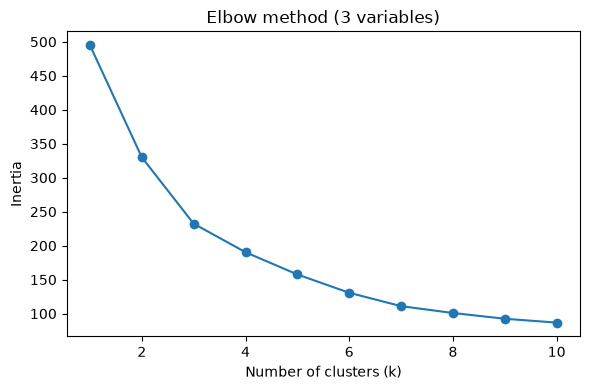

In [7]:
# Elbow method: within-cluster sum of squares (inertia) for k = 1..10
Ks = range(1, 11)
inertia = []
for k in Ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=0)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(Ks, inertia, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow method (3 variables)")
plt.tight_layout()
plt.savefig("figures/elbow_3var.png", dpi=150)
plt.show()

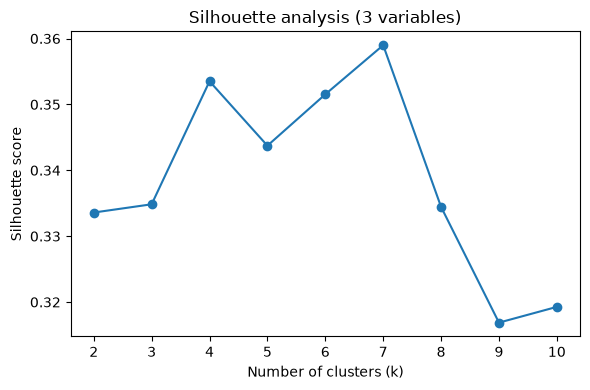

In [8]:
# Silhouette analysis for k = 2..10
silhouette = []
Ks = range(2, 11)
for k in Ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=0)
    labels = km.fit_predict(X_scaled)
    silhouette.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(6, 4))
plt.plot(Ks, silhouette, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette analysis (3 variables)")
plt.tight_layout()
plt.savefig("figures/silhouette_3var.png", dpi=150)
plt.show()

**Choosing k.** The elbow flattens between k = 2 and 4, so **k = 3** is chosen. The silhouette score here does
not give a clear answer (it peaks at a high k rather than at a small one), so it is treated as inconclusive and
the elbow drives the choice.

In [9]:
k = 3
kmeans = KMeans(n_clusters=k, n_init=20, random_state=0)
df_processed["cluster_3"] = kmeans.fit_predict(X_scaled)

# Centroids in standardised units (deviation from the overall mean, in standard deviations)
centroids1 = pd.DataFrame(kmeans.cluster_centers_, columns=vars1)
print(centroids1.round(2))

   log_gdp_pc  gdp_growth  pop_growth
0        0.92       -0.45       -0.44
1       -0.68       -0.57        1.03
2       -0.28        1.10       -0.63


In [10]:
# Centroids rescaled back to the original units
centroids_orig1 = pd.DataFrame(scaler_3.inverse_transform(kmeans.cluster_centers_), columns=vars1)
print(centroids_orig1.round(2))

   log_gdp_pc  gdp_growth  pop_growth
0        9.83        1.16        0.87
1        7.54        0.92        2.82
2        8.11        4.19        0.62


## 4. Clustering on 5 variables: adding tertiary enrolment and life expectancy

In [11]:
vars2 = ["log_gdp_pc", "gdp_growth", "pop_growth", "tert_enroll", "life_exp"]
X2 = df_processed[vars2]
scaler_5 = StandardScaler()
X_scaled2 = scaler_5.fit_transform(X2)

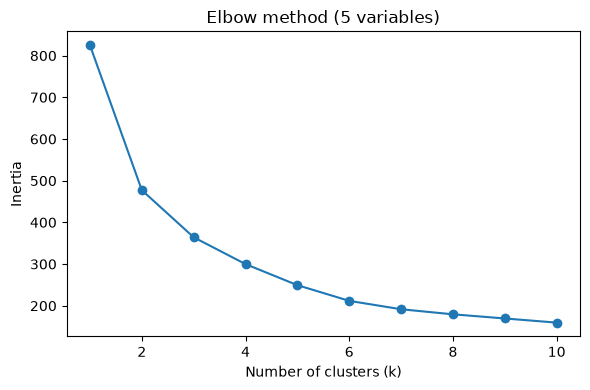

In [12]:
Ks = range(1, 11)
inertia = []
for k in Ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=0)
    km.fit(X_scaled2)
    inertia.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(Ks, inertia, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow method (5 variables)")
plt.tight_layout()
plt.savefig("figures/elbow_5var.png", dpi=150)
plt.show()

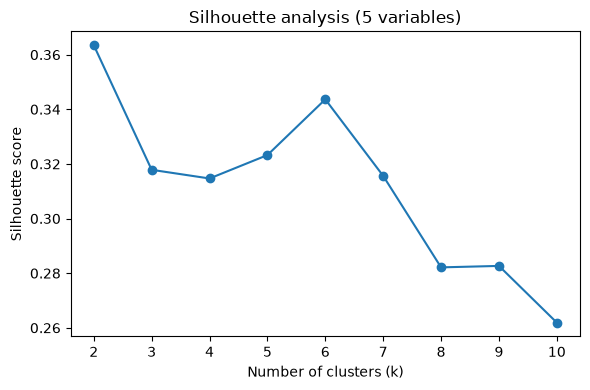

In [13]:
silhouette2 = []
Ks = range(2, 11)
for k in Ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=0)
    labels2 = km.fit_predict(X_scaled2)
    silhouette2.append(silhouette_score(X_scaled2, labels2))

plt.figure(figsize=(6, 4))
plt.plot(Ks, silhouette2, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette analysis (5 variables)")
plt.tight_layout()
plt.savefig("figures/silhouette_5var.png", dpi=150)
plt.show()

**Choosing k.** The elbow again bends at k = 2–3. With five variables the silhouette method is more
informative: it peaks at k = 2 with values between k = 3 and 6 also viable. Weighing both, **k = 3** is kept,
which also makes the two specifications directly comparable.

In [14]:
k = 3
kmeans2 = KMeans(n_clusters=k, n_init=20, random_state=0)
df_processed["cluster_5"] = kmeans2.fit_predict(X_scaled2)

centroids2 = pd.DataFrame(kmeans2.cluster_centers_, columns=vars2)
print(centroids2.round(2))

   log_gdp_pc  gdp_growth  pop_growth  tert_enroll  life_exp
0       -0.94       -0.39        0.80        -1.02     -1.21
1       -0.16        0.84       -0.63         0.09      0.18
2        1.11       -0.62       -0.03         0.90      0.98


In [15]:
# Centroids rescaled back to the original units
centroids_orig2 = pd.DataFrame(scaler_5.inverse_transform(kmeans2.cluster_centers_), columns=vars2)
print(centroids_orig2.round(2))

   log_gdp_pc  gdp_growth  pop_growth  tert_enroll  life_exp
0        7.16        1.27        2.51         7.60     59.69
1        8.29        3.67        0.62        37.12     71.65
2       10.10        0.82        1.41        58.81     78.57


## 5. Describing and comparing the clusters

### Where are the clusters geographically?

In [16]:
print("3-variable clustering")
print(pd.crosstab(df_processed["region"], df_processed["cluster_3"], margins=True))

3-variable clustering
cluster_3   0   1   2  All
region                    
EAS         9   1  11   21
ECS        25   1  23   49
LCN        12   4   5   21
MEA         6  15   2   23
NAC         2   0   0    2
SAS         0   1   5    6
SSF         3  34   6   43
All        57  56  52  165


In [17]:
print("5-variable clustering")
print(pd.crosstab(df_processed["region"], df_processed["cluster_5"], margins=True))

5-variable clustering
cluster_5   0   1   2  All
region                    
EAS         1  13   7   21
ECS         0  27  22   49
LCN         4   9   8   21
MEA         6   5  12   23
NAC         0   0   2    2
SAS         0   5   1    6
SSF        40   3   0   43
All        51  62  52  165


### Does country size vary across clusters?

In [18]:
print("3-variable clustering")
print(df_processed.groupby("cluster_3")["log_pop"].mean().round(2))
print("\n5-variable clustering")
print(df_processed.groupby("cluster_5")["log_pop"].mean().round(2))

3-variable clustering
cluster_3
0    15.76
1    15.94
2    15.99
Name: log_pop, dtype: float64

5-variable clustering
cluster_5
0    15.95
1    15.96
2    15.75
Name: log_pop, dtype: float64


### Policy: government and health expenditure shares of GDP

In [19]:
print("3-variable clustering")
print(df_processed.groupby("cluster_3")[["gov_gdp", "health_gdp"]].mean().round(2))
print("\n5-variable clustering")
print(df_processed.groupby("cluster_5")[["gov_gdp", "health_gdp"]].mean().round(2))

3-variable clustering
           gov_gdp  health_gdp
cluster_3                     
0            18.69        7.70
1            15.08        5.00
2            17.77        5.65

5-variable clustering
           gov_gdp  health_gdp
cluster_5                     
0            15.38        5.08
1            17.31        5.73
2            18.77        7.66


## 6. Interpretation

| Spec | Cluster | Profile (original units) | Label |
|---|---|---|---|
| 3-var | 0 | highest income (log GDP pc 9.83), slow growth (1.16%), low pop. growth | **Developed** |
| 3-var | 1 | lowest income (7.54), slow growth (0.92%), fastest pop. growth (2.82%) | **Developing** |
| 3-var | 2 | middle income (8.11), fastest growth (4.19%), lowest pop. growth | **Emerging** |
| 5-var | 0 | lowest income (7.16), tertiary enrolment 7.6%, life expectancy 59.7 | **Developing** |
| 5-var | 1 | middle income (8.29), fastest growth (3.67%), enrolment 37.1%, life exp. 71.7 | **Emerging** |
| 5-var | 2 | highest income (10.10), slow growth, enrolment 58.8%, life exp. 78.6 | **Developed** |

* **Adding human-development variables sharpens the split.** With tertiary enrolment and life expectancy, the
  developed cluster becomes richer on average and the developing cluster poorer – the two extra variables
  correlate strongly with income and pull the groups further apart.
* **Geography.** The developing cluster is concentrated in Sub-Saharan Africa (34 → 40 countries once
  human-development variables are added); the developed cluster in Europe, North America and parts of East Asia;
  the emerging cluster is the most geographically diverse and becomes the largest (62 countries) in the 5-variable
  specification.
* **Country size** barely differs across clusters – each mixes large and small countries.
* **Policy.** In both specifications, more developed clusters spend a larger share of GDP on government
  (≈18.7% vs ≈15.1–15.4%) and on health (≈7.7% vs ≈5.0–5.1%), consistent with a larger tax base.

## 7. Limitations

* **Selection bias from listwise deletion.** The 52 dropped countries are more likely to be poorer economies with
  weaker statistical capacity, so the results lean towards countries with better data.
* **Choice of k is a judgement call.** For the 3-variable model the silhouette score was inconclusive and k rests
  on the elbow method alone.
* **Outliers were kept deliberately** – a very high GDP per capita is a real value, not an error – but K-means
  centroids are means, so extreme countries pull centroids towards them.
* Long-run averages hide within-country change over 2000–2020.